You are a data analyst working for a tech company closely monitoring the AI tools market. You want to understand the evolving popularity of three major AI tools, ChatGPT, Gemini, and Microsoft Copilot, and identify which tool is gaining the most traction and how they compare over time.


<img src="ai_tools.jpg" align="center"/>

You'll work with real-world time series data that captures the global interest in these tools over several weeks. Your goal is to analyze this data, uncover patterns, and provide actionable insights to help your company make informed decisions. This might include determining where to focus marketing efforts, predicting future trends, or identifying potential areas for improvement.

Are you ready to help your company stay ahead of the curve in the competitive AI tools market? Let's get started!

### The Data

The Google Trends data is available as a CSV file `ai_tools_comparison.csv`.
The data contains the number of worldwide searches for chatGpt, Gemini, and Microsoft Copilot over the past 12 months as of September 2024. 
# <!--- Link to query: https://trends.google.com/trends/explore?q=chatgpt,gemini,%2Fg%2F11tsqm45vd&hl=en-US `-->`

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

# Load the data
trends = pd.read_csv('ai_tools_comparison.csv')

# Inspect the data
trends.head()

,week,chatgpt,gemini,microsoft_copilot
0,2023-08-27,56,3,1
1,2023-09-03,56,3,1
2,2023-09-10,63,3,1
3,2023-09-17,64,3,1
4,2023-09-24,66,3,1


In [75]:
# Start coding here
trends['week']= pd.to_datetime(trends['week'])
print(trends.head())
print(trends.shape)
print(trends.dtypes)
print(trends.isnull().sum())


# Use as many cells as you need

        week  chatgpt  gemini  microsoft_copilot
0 2023-08-27       56       3                  1
1 2023-09-03       56       3                  1
2 2023-09-10       63       3                  1
3 2023-09-17       64       3                  1
4 2023-09-24       66       3                  1
(54, 4)
week                 datetime64[ns]
chatgpt                       int64
gemini                        int64
microsoft_copilot             int64
dtype: object
week                 0
chatgpt              0
gemini               0
microsoft_copilot    0
dtype: int64


In [76]:
#1: Identify which AI tool is most consistent growth in the observed period
weekly_changes= trends[['chatgpt', 'gemini', 'microsoft_copilot']].diff()
print(weekly_changes.head())
print("Avarage weekly change:")
print( weekly_changes.mean())
print("Standard deviation")
print( weekly_changes.std())

growth_percentage = (weekly_changes > 0).sum()/weekly_changes.count()*100
print("Growth percentage")
print(growth_percentage)

for tool in weekly_changes.columns:
    growth = weekly_changes[tool] > 0
    groups = (growth != growth.shift()).cumsum()
    longest_streak = growth.groupby(groups).sum().max()

    print(tool, "Longest growth streak:", longest_streak)

most_consistent_tool = "ChatGPT"
print("Most consistent growth:", most_consistent_tool)






   chatgpt  gemini  microsoft_copilot
0      NaN     NaN                NaN
1      0.0     0.0                0.0
2      7.0     0.0                0.0
3      1.0     0.0                0.0
4      2.0     0.0                0.0
Avarage weekly change:
chatgpt              0.396226
gemini               0.207547
microsoft_copilot    0.037736
dtype: float64
Standard deviation
chatgpt              6.862214
gemini               1.609569
microsoft_copilot    0.758599
dtype: float64
Growth percentage
chatgpt              52.830189
gemini               28.301887
microsoft_copilot    22.641509
dtype: float64
chatgpt Longest growth streak: 7
gemini Longest growth streak: 3
microsoft_copilot Longest growth streak: 2
Most consistent growth: ChatGPT


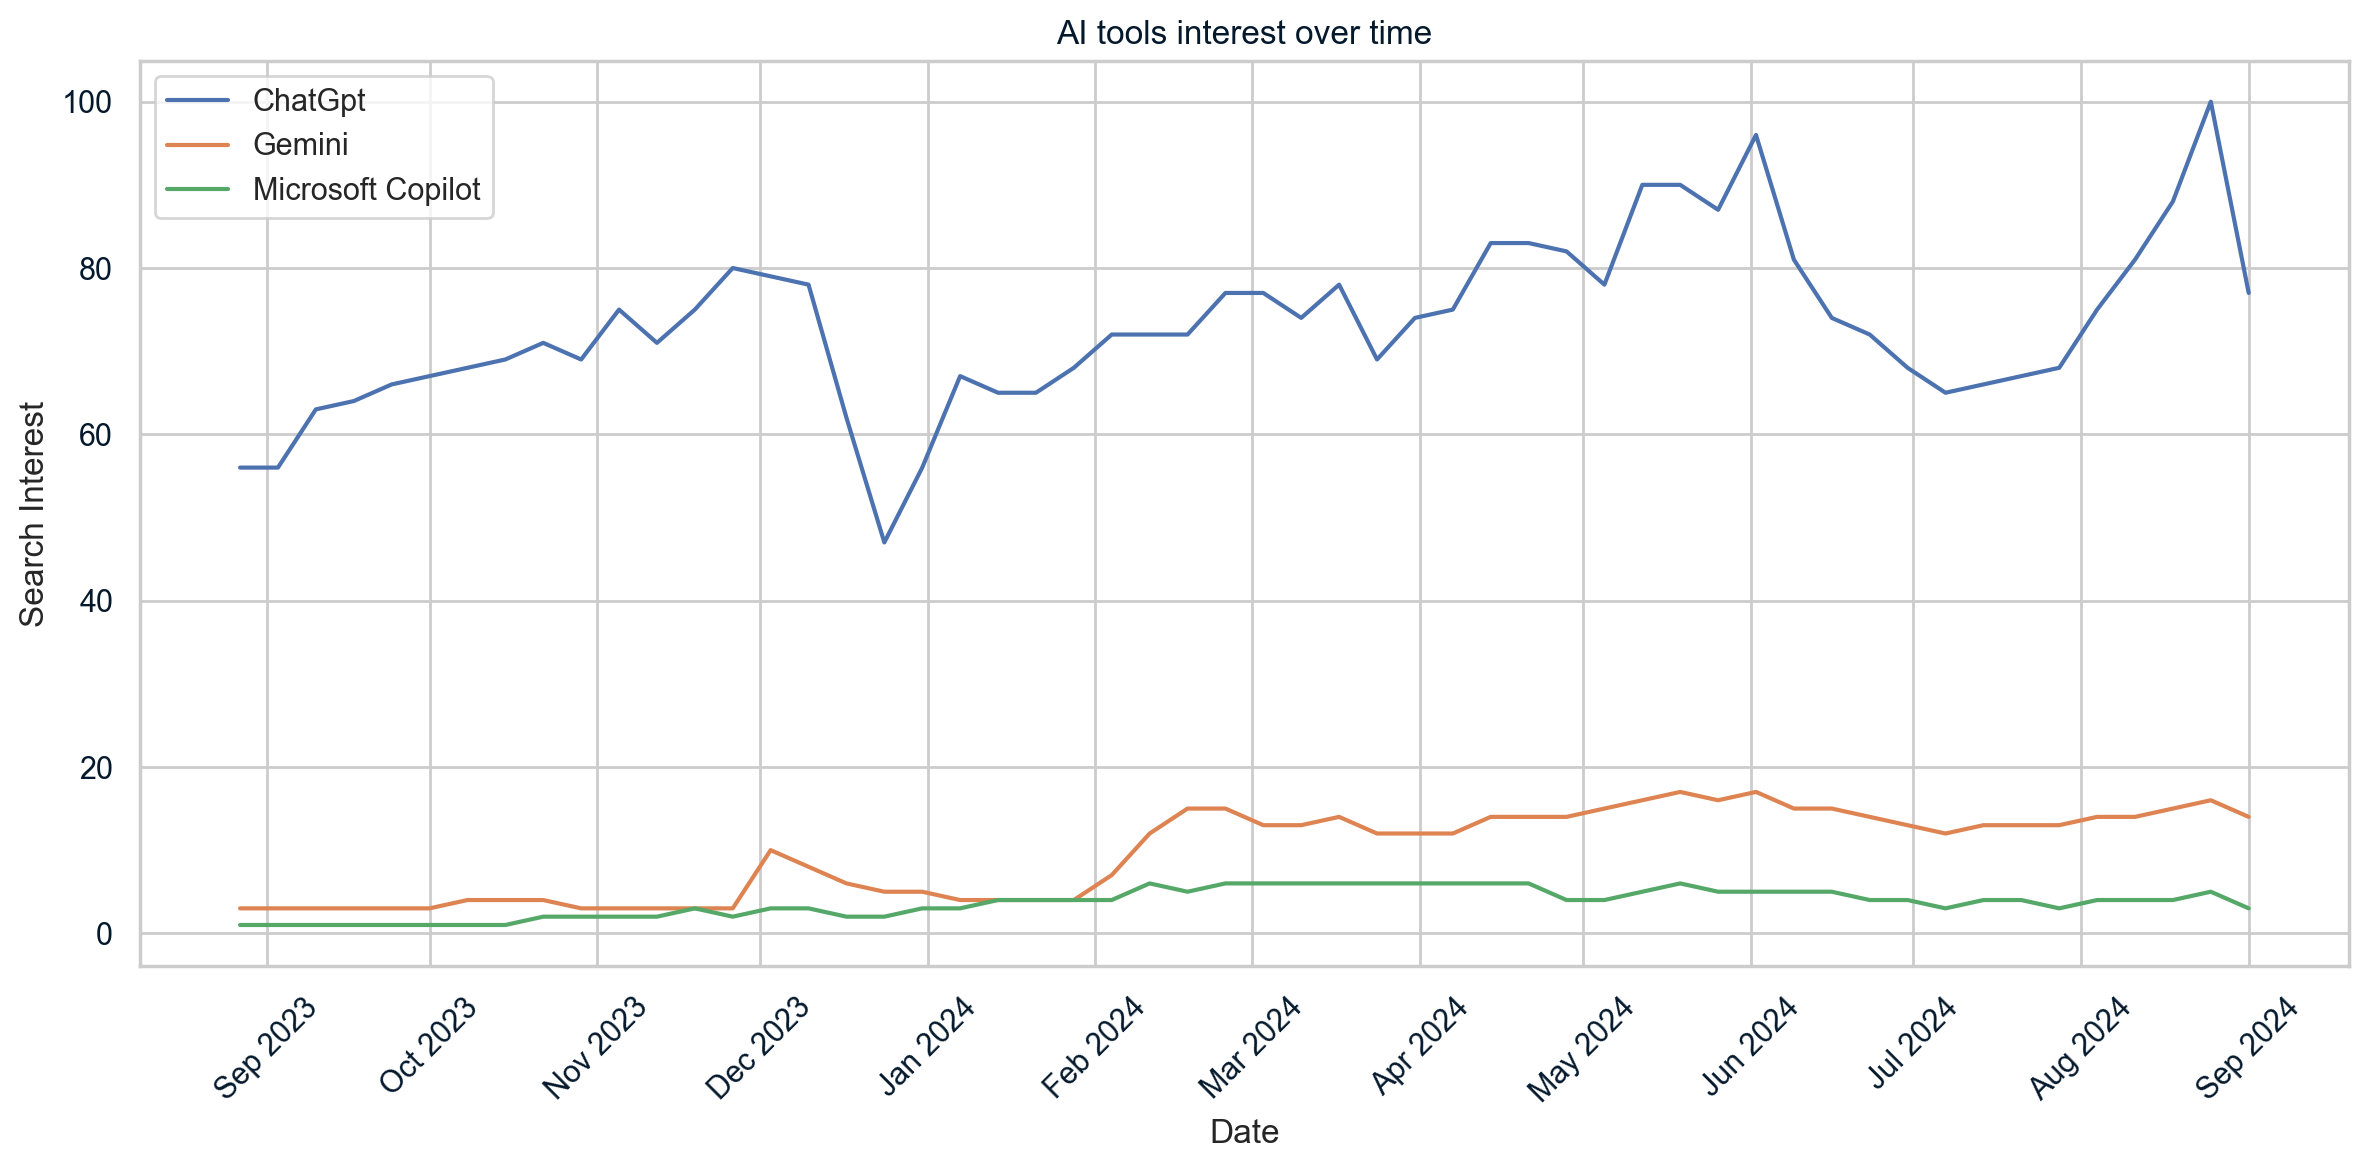

largest decline: 17
2023-12-24
ChatGPTs largest decline: December 2023


In [77]:
# 2: Visualize AI tools' search interest over time
# and identify the month when ChatGPT's interest reached its lowest point.
trends['week']= pd.to_datetime(trends['week'])
sns.set_theme(style='whitegrid')
plt.figure(figsize=(12,6))
sns.lineplot(data=trends,x='week',y='chatgpt',label='ChatGpt')
sns.lineplot(data=trends, x='week', y='gemini', label='Gemini')
sns.lineplot(data=trends, x='week', y='microsoft_copilot', label='Microsoft Copilot')

plt.title('AI tools interest over time')
plt.xlabel('Date')
plt.ylabel('Search Interest')
plt.legend()
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

biggest_dip = trends['chatgpt'].idxmin()
print("largest decline:", biggest_dip)
print(trends.loc[biggest_dip,'week'].date())


gpt_dip = trends.loc[biggest_dip, 'week'].strftime('%B %Y')
print('ChatGPTs largest decline:', gpt_dip)

In [78]:
# 3: Monthly Average Search Interest

trends['week'] = pd.to_datetime(trends['week'])

monthly_avg = trends.set_index('week')[
    ['chatgpt', 'gemini', 'microsoft_copilot']
].resample('MS').mean()

monthly_avg['overall_avg'] = monthly_avg.mean(axis=1)

print(monthly_avg['overall_avg'].sort_values(ascending=False))

best_month = monthly_avg['overall_avg'].idxmax().strftime('%B')
print(best_month)



week
2024-05-01    35.750000
2024-08-01    35.000000
2024-04-01    33.250000
2024-06-01    32.533333
2024-09-01    31.333333
2024-03-01    31.066667
2024-02-01    30.250000
2024-07-01    27.583333
2023-11-01    26.833333
2024-01-01    24.666667
2023-10-01    24.600000
2023-12-01    24.600000
2023-09-01    22.083333
2023-08-01    20.000000
Name: overall_avg, dtype: float64
May
